# Claim Severity Model Development

## 1. Data Preparation

This notebook develops the claim severity component of the General Insurance Capital & Risk Modelling project.

The objective is to model the distribution of individual claim amounts and provide a severity model suitable for subsequent aggregate-loss simulation and capital analysis.

The analysis uses the freMTPL2 severity dataset, containing individual claim amounts linked to policy identifiers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Load severity and frequency datasets
sev = pd.read_csv("../data/processed/freMTPL2sev.csv")
freq = pd.read_csv("../data/processed/freMTPL2freq.csv")

print(f"Severity records: {len(sev):,}")
print(f"Severity columns: {sev.shape[1]}")
print(f"Frequency records: {len(freq):,}")

sev.head()

Severity records: 26,444
Severity columns: 2
Frequency records: 677,991


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


In [2]:
# Validate severity dataset

severity_validation = pd.DataFrame({
    "DataType": sev.dtypes.astype(str),
    "Missing": sev.isna().sum(),
    "UniqueValues": sev.nunique()
})

print("SEVERITY DATA VALIDATION")
print(f"Observations: {len(sev):,}")
print(f"Missing claim amounts: {sev['ClaimAmount'].isna().sum():,}")
print(f"Claim amounts <= 0: {(sev['ClaimAmount'] <= 0).sum():,}")
print(f"Duplicate rows: {sev.duplicated().sum():,}")
print(f"Unique policies represented: {sev['IDpol'].nunique():,}")

severity_validation

SEVERITY DATA VALIDATION
Observations: 26,444
Missing claim amounts: 0
Claim amounts <= 0: 0
Duplicate rows: 235
Unique policies represented: 24,944


,DataType,Missing,UniqueValues
IDpol,int64,0,24944
ClaimAmount,float64,0,12255


In [3]:
# Summarise observed claim severity

claim_summary = sev["ClaimAmount"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
)

total_loss = sev["ClaimAmount"].sum()

print("CLAIM SEVERITY SUMMARY")
print(f"Number of claims: {len(sev):,}")
print(f"Total observed loss: {total_loss:,.2f}")
print(f"Mean severity: {sev['ClaimAmount'].mean():,.2f}")
print(f"Median severity: {sev['ClaimAmount'].median():,.2f}")
print(f"Maximum claim: {sev['ClaimAmount'].max():,.2f}")
print(f"Standard deviation: {sev['ClaimAmount'].std():,.2f}")
print(f"Skewness: {sev['ClaimAmount'].skew():,.2f}")

claim_summary

CLAIM SEVERITY SUMMARY
Number of claims: 26,444
Total observed loss: 59,909,216.50
Mean severity: 2,265.51
Median severity: 1,172.00
Maximum claim: 4,075,400.56
Standard deviation: 29,371.03
Skewness: 109.53


count    2.644400e+04
mean     2.265513e+03
std      2.937103e+04
min      1.000000e+00
50%      1.172000e+03
75%      1.212385e+03
90%      2.767604e+03
95%      4.765093e+03
99%      1.645122e+04
99.5%    3.437696e+04
99.9%    1.522232e+05
max      4.075401e+06
Name: ClaimAmount, dtype: float64

## 2. Tail Risk Assessment

Claim severity is strongly right-skewed, with a small number of very large losses relative to the typical claim.

Because the objective of this project is capital modelling, the upper tail requires particular attention. Extreme claims may have limited impact on average severity but substantial influence on high-percentile aggregate losses and capital requirements.

The following analysis measures the concentration of observed losses in the largest claims.

In [4]:
# Measure concentration of total losses in the largest claims

claims_sorted = sev["ClaimAmount"].sort_values(ascending=False).reset_index(drop=True)

concentration_results = []

for pct in [0.001, 0.005, 0.01, 0.05, 0.10]:
    n_claims = max(1, int(np.ceil(len(claims_sorted) * pct)))
    loss_amount = claims_sorted.iloc[:n_claims].sum()

    concentration_results.append({
        "TopClaims": f"{pct * 100:g}%",
        "NumberOfClaims": n_claims,
        "LossAmount": loss_amount,
        "ShareOfTotalLoss": loss_amount / total_loss
    })

loss_concentration = pd.DataFrame(concentration_results)

loss_concentration["LossAmount"] = (
    loss_concentration["LossAmount"].round(2)
)

loss_concentration["ShareOfTotalLoss"] = (
    loss_concentration["ShareOfTotalLoss"].round(4)
)

loss_concentration

,TopClaims,NumberOfClaims,LossAmount,ShareOfTotalLoss
0,0.1%,27,12959412.53,0.2163
1,0.5%,133,19743176.05,0.3296
2,1%,265,22773883.74,0.3801
3,5%,1323,31208589.23,0.5209
4,10%,2645,35901267.75,0.5993


In [5]:
# Examine the largest individual claims

largest_claims = (
    sev.sort_values("ClaimAmount", ascending=False)
       .head(20)
       .reset_index(drop=True)
       .copy()
)

largest_claims.index = largest_claims.index + 1
largest_claims.index.name = "Rank"

largest_claims["ShareOfTotalLoss"] = (
    largest_claims["ClaimAmount"] / total_loss
)

largest_claims["ClaimAmount"] = largest_claims["ClaimAmount"].round(2)
largest_claims["ShareOfTotalLoss"] = (
    largest_claims["ShareOfTotalLoss"].round(4)
)

largest_claims

,IDpol,ClaimAmount,ShareOfTotalLoss
Rank,,,
1,1120377,4075400.56,0.0680
2,110846,1403057.40,0.0234
3,2141337,1301172.60,0.0217
4,3122016,774411.50,0.0129
5,2008127,390742.27,0.0065
6,3025890,369131.88,0.0062
7,1117644,307096.42,0.0051
8,158309,301635.49,0.0050
9,3075820,287423.00,0.0048


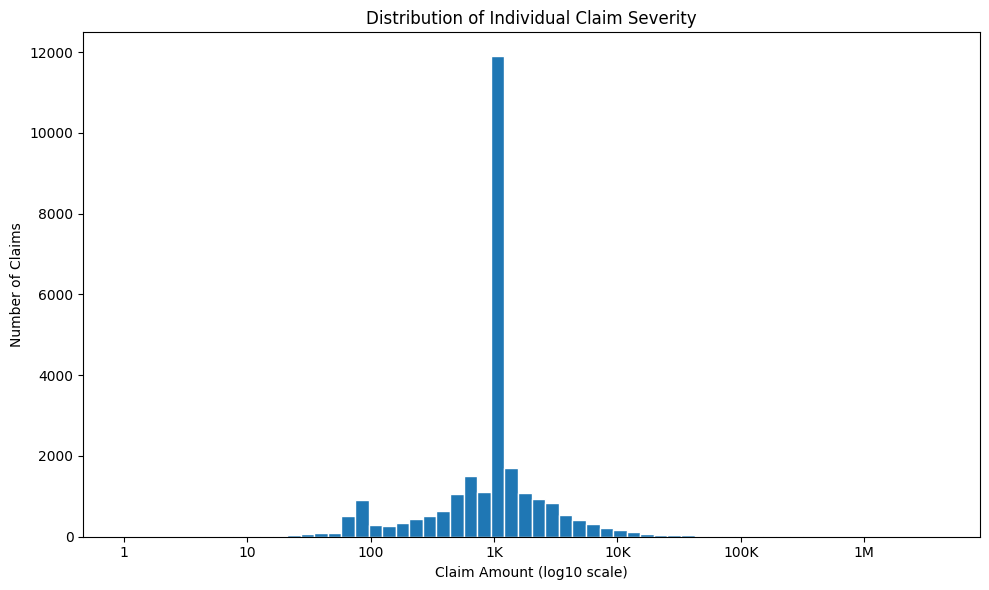

In [6]:
# Visualise observed claim severity on a logarithmic scale

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    np.log10(sev["ClaimAmount"]),
    bins=60,
    edgecolor="white"
)

ax.set_title("Distribution of Individual Claim Severity")
ax.set_xlabel("Claim Amount (log10 scale)")
ax.set_ylabel("Number of Claims")

# Convert log-scale positions back into monetary labels
ticks = [0, 1, 2, 3, 4, 5, 6]
ax.set_xticks(ticks)
ax.set_xticklabels(
    ["1", "10", "100", "1K", "10K", "100K", "1M"]
)

plt.tight_layout()
plt.show()

## 3. Candidate Severity Distribution Modelling

Two standard positive continuous distributions are initially considered:

- **Lognormal** — capable of representing substantial positive skewness and a relatively heavy right tail.
- **Gamma** — commonly used for positive, right-skewed insurance claim severity.

Both distributions are fitted to the observed individual claim amounts using maximum likelihood estimation. Their statistical fit and ability to represent the upper tail will then be compared before selecting a model for capital simulation.

In [7]:
# Fit Lognormal and Gamma distributions to observed claim severity

claim_amounts = sev["ClaimAmount"].values

# Force location = 0 because claim amounts are strictly positive
lognorm_shape, lognorm_loc, lognorm_scale = stats.lognorm.fit(
    claim_amounts,
    floc=0
)

gamma_shape, gamma_loc, gamma_scale = stats.gamma.fit(
    claim_amounts,
    floc=0
)

print("FITTED SEVERITY DISTRIBUTIONS")
print("\nLognormal")
print(f"Shape (sigma): {lognorm_shape:.6f}")
print(f"Scale:         {lognorm_scale:,.2f}")

print("\nGamma")
print(f"Shape:         {gamma_shape:.6f}")
print(f"Scale:         {gamma_scale:,.2f}")

FITTED SEVERITY DISTRIBUTIONS

Lognormal
Shape (sigma): 1.130002
Scale:         940.75

Gamma
Shape:         0.689137
Scale:         3,287.46


In [8]:
# Compare fitted severity distributions using log-likelihood and AIC

lognorm_loglik = np.sum(
    stats.lognorm.logpdf(
        claim_amounts,
        lognorm_shape,
        loc=0,
        scale=lognorm_scale
    )
)

gamma_loglik = np.sum(
    stats.gamma.logpdf(
        claim_amounts,
        gamma_shape,
        loc=0,
        scale=gamma_scale
    )
)

# Two estimated parameters for each model:
# shape and scale (location fixed at zero)
k = 2

lognorm_aic = 2 * k - 2 * lognorm_loglik
gamma_aic = 2 * k - 2 * gamma_loglik

severity_comparison = pd.DataFrame({
    "Distribution": ["Lognormal", "Gamma"],
    "LogLikelihood": [lognorm_loglik, gamma_loglik],
    "AIC": [lognorm_aic, gamma_aic]
})

severity_comparison.round({
    "LogLikelihood": 2,
    "AIC": 2
})

,Distribution,LogLikelihood,AIC
0,Lognormal,-221807.89,443619.78
1,Gamma,-229331.55,458667.10


In [9]:
# Compare observed and fitted upper-tail claim quantiles

quantiles = [0.90, 0.95, 0.99, 0.995, 0.999]

observed_quantiles = np.quantile(claim_amounts, quantiles)

lognorm_quantiles = stats.lognorm.ppf(
    quantiles,
    lognorm_shape,
    loc=0,
    scale=lognorm_scale
)

gamma_quantiles = stats.gamma.ppf(
    quantiles,
    gamma_shape,
    loc=0,
    scale=gamma_scale
)

tail_comparison = pd.DataFrame({
    "Quantile": ["90%", "95%", "99%", "99.5%", "99.9%"],
    "Observed": observed_quantiles,
    "Lognormal": lognorm_quantiles,
    "Gamma": gamma_quantiles
})

tail_comparison.round(2)

,Quantile,Observed,Lognormal,Gamma
0,90%,2767.60,4003.13,5707.75
1,95%,4765.09,6035.20,7754.85
2,99%,16451.22,13035.78,12647.85
3,99.5%,34376.96,17281.09,14792.58
4,99.9%,152223.24,30904.10,19825.76


In [11]:
# Examine candidate thresholds for extreme-value tail modelling

threshold_probs = [0.95, 0.975, 0.99, 0.995]

threshold_analysis = []

for p in threshold_probs:
    threshold = np.quantile(claim_amounts, p)
    exceedances = claim_amounts[claim_amounts > threshold]

    threshold_analysis.append({
        "Percentile": f"{p*100:g}%",
        "Threshold": threshold,
        "TailClaims": len(exceedances),
        "TailShare": len(exceedances) / len(claim_amounts),
        "MeanExcess": (exceedances - threshold).mean(),
        "MaximumClaim": exceedances.max()
    })

threshold_analysis = pd.DataFrame(threshold_analysis)

threshold_analysis.round({
    "Threshold": 2,
    "TailShare": 4,
    "MeanExcess": 2,
    "MaximumClaim": 2
})

,Percentile,Threshold,TailClaims,TailShare,MeanExcess,MaximumClaim
0,95%,4765.09,1323,0.050,18824.17,4075400.56
1,97.5%,8156.01,662,0.025,32866.95,4075400.56
2,99%,16451.22,265,0.010,69487.96,4075400.56
3,99.5%,34376.96,133,0.005,114067.97,4075400.56


In [12]:
# Fit Generalized Pareto Distribution across candidate thresholds

gpd_results = []

for p in threshold_probs:
    threshold = np.quantile(claim_amounts, p)

    excess_losses = claim_amounts[claim_amounts > threshold] - threshold

    shape, loc, scale = stats.genpareto.fit(
        excess_losses,
        floc=0
    )

    gpd_results.append({
        "Percentile": f"{p*100:g}%",
        "Threshold": threshold,
        "TailClaims": len(excess_losses),
        "ShapeXi": shape,
        "ScaleBeta": scale
    })

gpd_results = pd.DataFrame(gpd_results)

gpd_results.round({
    "Threshold": 2,
    "ShapeXi": 4,
    "ScaleBeta": 2
})

,Percentile,Threshold,TailClaims,ShapeXi,ScaleBeta
0,95%,4765.09,1323,0.9040,3479.08
1,97.5%,8156.01,662,1.0327,5551.67
2,99%,16451.22,265,0.8201,18144.86
3,99.5%,34376.96,133,0.7980,31968.14


In [13]:
# Validate 97.5% GPD tail model against observed extreme quantiles

tail_threshold_prob = 0.975
tail_threshold = np.quantile(claim_amounts, tail_threshold_prob)

tail_excess = claim_amounts[claim_amounts > tail_threshold] - tail_threshold

gpd_shape, _, gpd_scale = stats.genpareto.fit(
    tail_excess,
    floc=0
)

# Unconditional claim quantiles to validate
validation_probs = [0.99, 0.995, 0.999]

results = []

for p in validation_probs:

    # Convert unconditional percentile to conditional tail probability
    conditional_p = (
        (p - tail_threshold_prob) /
        (1 - tail_threshold_prob)
    )

    fitted_claim = tail_threshold + stats.genpareto.ppf(
        conditional_p,
        c=gpd_shape,
        loc=0,
        scale=gpd_scale
    )

    observed_claim = np.quantile(claim_amounts, p)

    results.append({
        "Quantile": f"{p*100:g}%",
        "Observed": observed_claim,
        "GPD": fitted_claim,
        "GPD_to_Observed": fitted_claim / observed_claim
    })

gpd_validation = pd.DataFrame(results)

gpd_validation.round({
    "Observed": 2,
    "GPD": 2,
    "GPD_to_Observed": 3
})

,Quantile,Observed,GPD,GPD_to_Observed
0,99%,16451.22,16628.75,1.011
1,99.5%,34376.96,31112.72,0.905
2,99.9%,152223.24,152104.42,0.999


### Severity Model Selection

The observed claim severity distribution is highly right-skewed and exhibits substantial large-loss concentration. A single-distribution comparison showed that the Lognormal model provided a materially better overall fit than the Gamma distribution based on log-likelihood and AIC.

However, both single distributions materially underestimated the extreme upper tail. At the empirical 99.9th percentile, observed severity was approximately £152,223, compared with approximately £30,904 under the fitted Lognormal model.

A peaks-over-threshold approach was therefore adopted for large claims. The 97.5th percentile (£8,156.01) was selected as the tail threshold, retaining 662 exceedances for estimation. A Generalized Pareto Distribution fitted to excess losses produced a shape parameter ξ of 1.0327 and scale parameter β of £5,551.67.

Tail validation showed close agreement with observed extreme quantiles, including approximately £152,104 at the 99.9th percentile compared with an observed £152,223.

The severity framework used for subsequent capital modelling is therefore a composite model: Lognormal for the body of the claim distribution and GPD for claims above the 97.5th-percentile threshold. The very heavy fitted GPD tail is treated as a material model-risk consideration in subsequent simulation and sensitivity analysis.

## 4. Composite Severity Model

### 4.1 Composite Severity Simulation

The selected severity framework combines a truncated Lognormal body with a Generalized Pareto tail above the empirical 97.5th-percentile threshold. This section constructs the composite severity sampler and validates its behaviour before it is incorporated into the aggregate-loss capital model.

In [14]:
# Construct composite Lognormal-GPD severity sampler

rng = np.random.default_rng(42)

body_probability = 0.975
tail_probability = 1 - body_probability

severity_threshold = np.quantile(claim_amounts, body_probability)

def simulate_severity(n, rng):
    """
    Simulate individual claim severities from the composite model:
    truncated Lognormal body + GPD upper tail.
    """

    is_tail = rng.random(n) >= body_probability
    simulated = np.empty(n)

    # BODY: draw from Lognormal conditional on X <= threshold
    n_body = (~is_tail).sum()

    if n_body > 0:
        body_cdf_threshold = stats.lognorm.cdf(
            severity_threshold,
            s=lognorm_shape,
            loc=0,
            scale=lognorm_scale
        )

        u_body = rng.uniform(
            0,
            body_cdf_threshold,
            size=n_body
        )

        simulated[~is_tail] = stats.lognorm.ppf(
            u_body,
            s=lognorm_shape,
            loc=0,
            scale=lognorm_scale
        )

    # TAIL: threshold + GPD excess
    n_tail = is_tail.sum()

    if n_tail > 0:
        simulated[is_tail] = severity_threshold + stats.genpareto.rvs(
            c=gpd_shape,
            loc=0,
            scale=gpd_scale,
            size=n_tail,
            random_state=rng
        )

    return simulated

In [15]:
# Validate composite severity distribution

simulated_severity = simulate_severity(
    n=500_000,
    rng=rng
)

validation_quantiles = [0.50, 0.90, 0.95, 0.975, 0.99, 0.995, 0.999]

composite_validation = pd.DataFrame({
    "Quantile": [f"{p*100:g}%" for p in validation_quantiles],
    "Observed": np.quantile(claim_amounts, validation_quantiles),
    "CompositeModel": np.quantile(simulated_severity, validation_quantiles)
})

composite_validation["Model_to_Observed"] = (
    composite_validation["CompositeModel"] /
    composite_validation["Observed"]
)

print("COMPOSITE SEVERITY MODEL VALIDATION")
print(f"Simulated claims: {len(simulated_severity):,}")
print(f"Observed mean severity: £{claim_amounts.mean():,.2f}")
print(f"Simulated mean severity: £{simulated_severity.mean():,.2f}")
print(f"Simulated maximum claim: £{simulated_severity.max():,.2f}")

composite_validation.round({
    "Observed": 2,
    "CompositeModel": 2,
    "Model_to_Observed": 3
})

COMPOSITE SEVERITY MODEL VALIDATION
Simulated claims: 500,000
Observed mean severity: £2,265.51
Simulated mean severity: £65,140.63
Simulated maximum claim: £31,137,680,821.96


,Quantile,Observed,CompositeModel,Model_to_Observed
0,50%,1172.00,937.47,0.800
1,90%,2767.60,3930.65,1.420
2,95%,4765.09,5854.59,1.229
3,97.5%,8156.01,8163.52,1.001
4,99%,16451.22,16861.79,1.025
5,99.5%,34376.96,31255.86,0.909
6,99.9%,152223.24,158395.79,1.041


### 4.2 Tail Model Risk and Severity Limits

The unrestricted GPD tail produces extreme extrapolation because the fitted shape parameter exceeds one. Although the model provides a strong fit to observed upper quantiles, unrestricted extrapolation generates exceptionally large simulated claims and an unstable expected severity.

For capital modelling, this represents material model risk. The following analysis therefore evaluates the effect of alternative maximum claim assumptions before selecting a severity specification for aggregate-loss simulation.

In [16]:
# Assess sensitivity of simulated severity to alternative claim limits

observed_max = claim_amounts.max()

claim_limits = [
    observed_max,
    5_000_000,
    10_000_000,
    25_000_000,
    50_000_000
]

limit_sensitivity = []

for limit in claim_limits:

    limited_severity = np.minimum(simulated_severity, limit)

    limit_sensitivity.append({
        "ClaimLimit": limit,
        "MeanSeverity": limited_severity.mean(),
        "Q99": np.quantile(limited_severity, 0.99),
        "Q99_5": np.quantile(limited_severity, 0.995),
        "Q99_9": np.quantile(limited_severity, 0.999),
        "Maximum": limited_severity.max(),
        "ClaimsAtLimit": (simulated_severity >= limit).sum(),
        "ShareAtLimit": (simulated_severity >= limit).mean()
    })

limit_sensitivity = pd.DataFrame(limit_sensitivity)

limit_sensitivity.round({
    "ClaimLimit": 2,
    "MeanSeverity": 2,
    "Q99": 2,
    "Q99_5": 2,
    "Q99_9": 2,
    "Maximum": 2,
    "ShareAtLimit": 6
})

,ClaimLimit,MeanSeverity,Q99,Q99_5,Q99_9,Maximum,ClaimsAtLimit,ShareAtLimit
0,4075400.56,2595.62,16861.79,31255.86,158395.79,4075400.56,18,0.000036
1,5000000.00,2626.04,16861.79,31255.86,158395.79,5000000.00,15,0.000030
2,10000000.00,2729.45,16861.79,31255.86,158395.79,10000000.00,8,0.000016
3,25000000.00,2845.48,16861.79,31255.86,158395.79,25000000.00,2,0.000004
4,50000000.00,2945.48,16861.79,31255.86,158395.79,50000000.00,2,0.000004


### 4.3 Final Severity Model Specification

The base severity model uses a composite distribution consisting of a Lognormal body and a Generalized Pareto Distribution (GPD) tail above the 97.5th percentile threshold (£8,156.01).

The GPD provides a substantially better representation of the observed extreme tail than the standalone Lognormal or Gamma distributions. However, the estimated GPD shape parameter exceeds one, producing an extremely heavy unrestricted tail and unstable simulated mean severity.

For the base capital model, simulated individual losses are therefore limited to £4,075,400.56, equal to the largest observed claim in the dataset. This is a modelling assumption rather than an observed contractual policy limit.

Alternative limits of £5m, £10m, £25m and £50m are retained for sensitivity testing to quantify the effect of tail-model uncertainty on the resulting capital requirement.

In [17]:
# Final base severity specification for capital modelling

BASE_CLAIM_LIMIT = claim_amounts.max()

base_simulated_severity = np.minimum(
    simulated_severity,
    BASE_CLAIM_LIMIT
)

print("FINAL BASE SEVERITY MODEL")
print(f"Body distribution:        Lognormal")
print(f"Tail distribution:        GPD")
print(f"Tail threshold:           £{tail_threshold:,.2f}")
print(f"Maximum modelling loss:   £{BASE_CLAIM_LIMIT:,.2f}")
print(f"Observed mean severity:   £{claim_amounts.mean():,.2f}")
print(f"Modelled mean severity:   £{base_simulated_severity.mean():,.2f}")
print(
    f"Mean severity difference: "
    f"{base_simulated_severity.mean() / claim_amounts.mean() - 1:.2%}"
)

FINAL BASE SEVERITY MODEL
Body distribution:        Lognormal
Tail distribution:        GPD
Tail threshold:           £8,156.01
Maximum modelling loss:   £4,075,400.56
Observed mean severity:   £2,265.51
Modelled mean severity:   £2,595.62
Mean severity difference: 14.57%


### 4.4 Mean Calibration

The capped composite severity model reproduces the observed upper-tail behaviour but produces a mean severity 14.57% above the historical portfolio mean.

Because the capital model is intended to distinguish expected loss from unexpected loss, the base severity distribution is calibrated to the observed portfolio mean while retaining the relative shape and tail behaviour of the composite model.

This calibration anchors expected severity to the historical portfolio experience. Alternative severity and claim-limit assumptions will subsequently be examined through sensitivity and stress testing.

In [18]:
# Calibrate composite severity distribution to observed mean severity

observed_mean_severity = claim_amounts.mean()
uncalibrated_mean_severity = base_simulated_severity.mean()

severity_calibration_factor = (
    observed_mean_severity / uncalibrated_mean_severity
)

calibrated_severity = (
    base_simulated_severity * severity_calibration_factor
)

print("SEVERITY MEAN CALIBRATION")
print(f"Observed mean severity:      £{observed_mean_severity:,.2f}")
print(f"Pre-calibration mean:        £{uncalibrated_mean_severity:,.2f}")
print(f"Calibration factor:          {severity_calibration_factor:.6f}")
print(f"Calibrated mean severity:    £{calibrated_severity.mean():,.2f}")
print(f"Calibrated maximum severity: £{calibrated_severity.max():,.2f}")

# Validate important quantiles after calibration
quantiles = [0.50, 0.90, 0.95, 0.975, 0.99, 0.995, 0.999]

calibrated_validation = pd.DataFrame({
    "Quantile": [f"{q*100:g}%" for q in quantiles],
    "Observed": np.quantile(claim_amounts, quantiles),
    "CalibratedModel": np.quantile(calibrated_severity, quantiles)
})

calibrated_validation["Model_to_Observed"] = (
    calibrated_validation["CalibratedModel"]
    / calibrated_validation["Observed"]
)

calibrated_validation.round({
    "Observed": 2,
    "CalibratedModel": 2,
    "Model_to_Observed": 3
})

SEVERITY MEAN CALIBRATION
Observed mean severity:      £2,265.51
Pre-calibration mean:        £2,595.62
Calibration factor:          0.872822
Calibrated mean severity:    £2,265.51
Calibrated maximum severity: £3,557,098.45


,Quantile,Observed,CalibratedModel,Model_to_Observed
0,50%,1172.00,818.25,0.698
1,90%,2767.60,3430.76,1.240
2,95%,4765.09,5110.01,1.072
3,97.5%,8156.01,7125.30,0.874
4,99%,16451.22,14717.34,0.895
5,99.5%,34376.96,27280.79,0.794
6,99.9%,152223.24,138251.30,0.908


### 4.5 Final Severity Model Selection

Mean calibration successfully aligned simulated average severity with the historical mean of £2,265.51. However, applying a uniform calibration factor materially weakened the fit to the upper tail, including underestimation at the 97.5%, 99%, 99.5% and 99.9% quantiles.

Because the objective of this project is capital and extreme-loss modelling, preservation of credible upper-tail behaviour is prioritised over exact replication of historical mean severity.

The final base severity specification therefore uses:

- Lognormal distribution for the body of the loss distribution.
- GPD for losses above the 97.5th percentile threshold of £8,156.01.
- Maximum modelled individual loss of £4,075,400.56, equal to the maximum observed claim.
- Uncalibrated capped composite mean severity of £2,595.62.

The 14.57% difference between modelled and observed mean severity is retained transparently as model conservatism and will be considered through sensitivity analysis. Alternative claim limits will also be tested to assess tail-model uncertainty.

This severity model is intended for analytical capital modelling and should not be interpreted as a regulatory capital model or as evidence of an actual contractual policy limit.

In [19]:
final_severity_sample = base_simulated_severity.copy()

print(f"Final severity sample: {len(final_severity_sample):,}")
print(f"Final mean severity: £{final_severity_sample.mean():,.2f}")
print(f"Final maximum severity: £{final_severity_sample.max():,.2f}")

Final severity sample: 500,000
Final mean severity: £2,595.62
Final maximum severity: £4,075,400.56
